# Titanic EDA

Import libraries

In [455]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Import dataset

In [456]:
df = pd.read_csv('titanic.csv')
df.sample(5)

,PassengerId,Survived,Pclass,Name,Gender,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
359,360,1,3,"Mockler, Miss. Helen Mary ""Ellie""",female,NaN,0,0,330980,7.8792,NaN,Q
731,732,0,3,"Hassan, Mr. Houssein G N",male,11.0,0,0,2699,18.7875,NaN,C
716,717,1,1,"Endres, Miss. Caroline Louise",female,38.0,0,0,PC 17757,227.5250,C45,C
425,426,0,3,"Wiseman, Mr. Phillippe",male,NaN,0,0,A/4. 34244,7.2500,NaN,S
647,648,1,1,"Simonius-Blumer, Col. Oberst Alfons",male,56.0,0,0,13213,35.5000,A26,C


In [457]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [458]:
df.dtypes

PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Gender          object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object

Prepare Age column (missing values)

In [459]:
df[df['Age'].isnull()]

,PassengerId,Survived,Pclass,Name,Gender,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
17,18,1,2,"Williams, Mr. Charles Eugene",male,NaN,0,0,244373,13.0000,NaN,S
19,20,1,3,"Masselmani, Mrs. Fatima",female,NaN,0,0,2649,7.2250,NaN,C
26,27,0,3,"Emir, Mr. Farred Chehab",male,NaN,0,0,2631,7.2250,NaN,C
28,29,1,3,"O'Dwyer, Miss. Ellen ""Nellie""",female,NaN,0,0,330959,7.8792,NaN,Q
...,...,...,...,...,...,...,...,...,...,...,...,...
859,860,0,3,"Razi, Mr. Raihed",male,NaN,0,0,2629,7.2292,NaN,C
863,864,0,3,"Sage, Miss. Dorothy Edith ""Dolly""",female,NaN,8,2,CA. 2343,69.5500,NaN,S
868,869,0,3,"van Melkebeke, Mr. Philemon",male,NaN,0,0,345777,9.5000,NaN,S
878,879,0,3,"Laleff, Mr. Kristo",male,NaN,0,0,349217,7.8958,NaN,S


In [460]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Gender           0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [461]:
df['Age'].fillna(df['Age'].mean(), inplace=True)

In [462]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Gender           0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

Prepare Parch column (to ParCh)

In [463]:
df['ParCh'] = df['Parch']
df = df.filter(['PassengerId', 'Survived', 'Pclass', 'Name', 'Gender', 'Age', 'SibSp', 'ParCh', 'Ticket', 'Fare', 'Cabin', 'Embarked'])
df.head(1)

,PassengerId,Survived,Pclass,Name,Gender,Age,SibSp,ParCh,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.25,NaN,S


Gender to 0 or 1

In [464]:
df_num = df.copy()
df_num['Gender'] = df['Gender'].replace(['male', 'female'], [0, 1])

C:\Users\Soheil\AppData\Local\Temp\ipykernel_14344\2719194315.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_num['Gender'] = df['Gender'].replace(['male', 'female'], [0, 1])


In [465]:
df_num.sample(5)

,PassengerId,Survived,Pclass,Name,Gender,Age,SibSp,ParCh,Ticket,Fare,Cabin,Embarked
382,383,0,3,"Tikkanen, Mr. Juho",0,32.000000,0,0,STON/O 2. 3101293,7.9250,NaN,S
408,409,0,3,"Birkeland, Mr. Hans Martin Monsen",0,21.000000,0,0,312992,7.7750,NaN,S
81,82,1,3,"Sheerlinck, Mr. Jan Baptist",0,29.000000,0,0,345779,9.5000,NaN,S
527,528,0,1,"Farthing, Mr. John",0,29.699118,0,0,PC 17483,221.7792,C95,S
377,378,0,1,"Widener, Mr. Harry Elkins",0,27.000000,0,2,113503,211.5000,C82,C


In [466]:
drop_list = []

for i in range(len(df_num.dtypes)):
    if df_num.dtypes.values[i] != 'float64' and df_num.dtypes.values[i] != 'int64':
        drop_list.append(str(df_num.dtypes.keys()[i]))

df_num.drop(columns=drop_list, inplace=True)

In [467]:
df_num

,PassengerId,Survived,Pclass,Gender,Age,SibSp,ParCh,Fare
0,1,0,3,0,22.000000,1,0,7.2500
1,2,1,1,1,38.000000,1,0,71.2833
2,3,1,3,1,26.000000,0,0,7.9250
3,4,1,1,1,35.000000,1,0,53.1000
4,5,0,3,0,35.000000,0,0,8.0500
...,...,...,...,...,...,...,...,...
886,887,0,2,0,27.000000,0,0,13.0000
887,888,1,1,1,19.000000,0,0,30.0000
888,889,0,3,1,29.699118,1,2,23.4500
889,890,1,1,0,26.000000,0,0,30.0000


Survived to survived or died

In [468]:
df['Survived'].replace([0, 1], ['died', 'survived'], inplace=True)

In [469]:
df.head()

,PassengerId,Survived,Pclass,Name,Gender,Age,SibSp,ParCh,Ticket,Fare,Cabin,Embarked
0,1,died,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,survived,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,survived,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,survived,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,died,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


Understand dataset

In [470]:
df_num.corr()

,PassengerId,Survived,Pclass,Gender,Age,SibSp,ParCh,Fare
PassengerId,1.000000,-0.005007,-0.035144,-0.042939,0.033207,-0.057527,-0.001652,0.012658
Survived,-0.005007,1.000000,-0.338481,0.543351,-0.069809,-0.035322,0.081629,0.257307
Pclass,-0.035144,-0.338481,1.000000,-0.131900,-0.331339,0.083081,0.018443,-0.549500
Gender,-0.042939,0.543351,-0.131900,1.000000,-0.084153,0.114631,0.245489,0.182333
Age,0.033207,-0.069809,-0.331339,-0.084153,1.000000,-0.232625,-0.179191,0.091566
SibSp,-0.057527,-0.035322,0.083081,0.114631,-0.232625,1.000000,0.414838,0.159651
ParCh,-0.001652,0.081629,0.018443,0.245489,-0.179191,0.414838,1.000000,0.216225
Fare,0.012658,0.257307,-0.549500,0.182333,0.091566,0.159651,0.216225,1.000000


<Axes: >

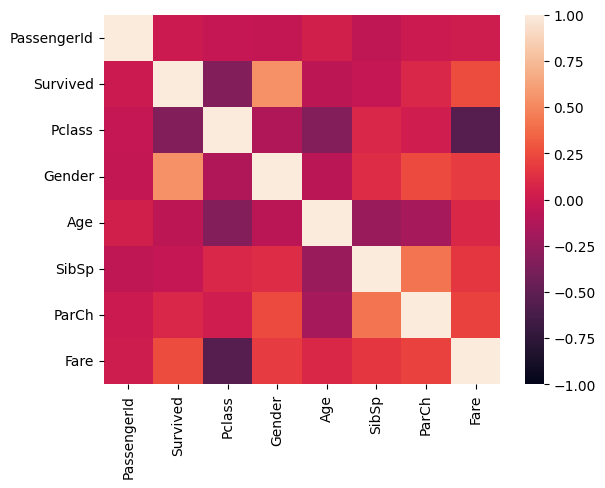

In [471]:
sns.heatmap(df_num.corr(), vmin=-1,vmax=1)

Gneder and Survived

In [472]:
gender_survived = pd.DataFrame(df.groupby('Gender')['Survived'].value_counts())
gender_survived.sort_values(by=['Gender', 'Survived'] ,inplace=True, ascending=False)
gender_survived

count
Gender Survived       
male   survived    109
       died        468
female survived    233
       died         81

In [473]:
gender_survived_corr = df_num[['Gender', 'Survived']].corr()
gender_survived_corr

,Gender,Survived
Gender,1.000000,0.543351
Survived,0.543351,1.000000


The correlation between Gender and Survived is 0.543351

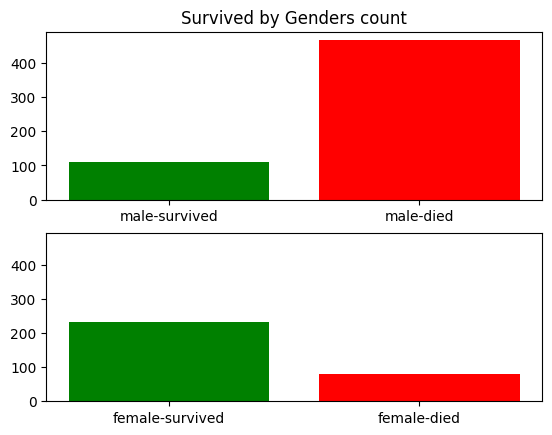

In [474]:
fig, ax = plt.subplots(2, sharey=True)

ax[0].bar(['male-survived', 'male-died'], gender_survived['count']['male'], color=['green', 'red'])
ax[1].bar(['female-survived', 'female-died'], gender_survived['count']['female'], color=['green', 'red'])
ax[0].set_title('Survived by Genders count')
plt.show()

In [475]:
gender_survived_density = gender_survived.copy()
gs_count = gender_survived['count']
gender_survived_density['count']['female'] = ((gs_count['female'] / gs_count['female'].sum()) * 100).round(2)
gender_survived_density['count']['male'] = ((gs_count['male'] / gs_count['male'].sum()) * 100).round(2)

C:\Users\Soheil\AppData\Local\Temp\ipykernel_14344\2452079169.py:3: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[74.2 25.8]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  gender_survived_density['count']['female'] = ((gs_count['female'] / gs_count['female'].sum()) * 100).round(2)


In [476]:
gender_survived_density

count
Gender Survived       
male   survived  18.89
       died      81.11
female survived  74.20
       died      25.80

In [477]:
ct_gs = pd.crosstab(df['Gender'], df['Survived'], margins=True)
ct_gs

Survived,died,survived,All
Gender,,,
female,81,233,314
male,468,109,577
All,549,342,891


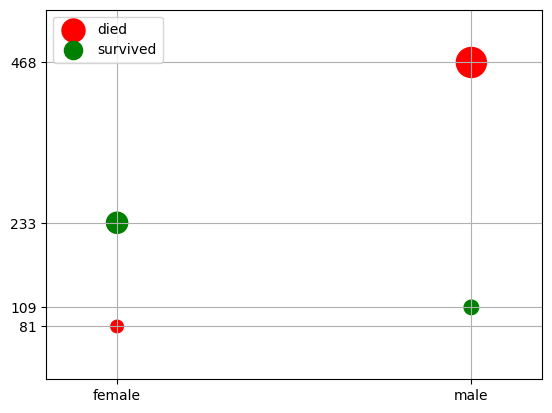

In [482]:
yticks = np.array(np.array([ct_gs['died'][:-1],ct_gs['survived'][:-1]]).flat)
plt.scatter(['female', 'male'],ct_gs['died'][:-1], s=ct_gs['died'][:-1], c='red')
plt.scatter(['female', 'male'],ct_gs['survived'][:-1], s=ct_gs['survived'][:-1], c='green')
plt.margins(0.2)
plt.grid()
plt.yticks(yticks)
plt.legend(['died', 'survived'])